# Livrable 4 · Analyse clients et gestion des sinistres

Toutes les valeurs proviennent des marts de l'entrepôt (`make run`) :
- `mart_retention_contrats` et `mart_retention_clients` pour les cohortes ;
- `mart_clients` pour la valeur client ;
- `mart_sinistres` pour les délais et les audits.

Chaque chiffre est accompagné de **la population à laquelle il s'applique**.

In [1]:
import sys, pathlib
RACINE = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(RACINE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from analyse.indicateurs import lire, ic_poisson

FIGURES = RACINE / "docs" / "figures"
plt.rcParams.update({"axes.titlesize": 10})
pd.set_option("display.max_columns", 30)

ret = lire("SELECT * FROM marts.mart_retention_contrats ORDER BY ALL")
ret_cli = lire("SELECT * FROM marts.mart_retention_clients ORDER BY ALL")
cl = lire("SELECT * FROM marts.mart_clients ORDER BY client_id")
si = lire("SELECT * FROM marts.mart_sinistres ORDER BY sinistre_id")
print(f"{ret['nb_contrats'].sum() // 5:,} contrats, {len(cl):,} clients avec au moins un contrat valide, {len(si):,} sinistres valides")

20,219 contrats, 14,977 clients avec au moins un contrat valide, 2,783 sinistres valides


## 1. Cohortes et multi-détention

### Matrice de rétention par cohorte annuelle de souscription

**Définition.** Un contrat est retenu à *n* ans s'il n'est pas résilié à son *n*-ième anniversaire.

**Population.** Une cellule n'est affichée que si **tous** les contrats de la cohorte ont atteint cet anniversaire avant le 30/06/2025 : la période doit être entièrement observable. Par conséquent :
- la cohorte 2023 n'a qu'un an d'observation complet ;
- les cohortes 2024 et 2025 n'en ont aucun.

In [2]:
complet = ret[ret["cellule_complete"]]
matrice = (complet.groupby(["produit", "cohorte", "anciennete_annees"])[["nb_retenus", "nb_contrats"]].sum()
           .assign(retention=lambda d: (100 * d["nb_retenus"] / d["nb_contrats"]).round(1))["retention"]
           .unstack("anciennete_annees"))
matrice.columns = [f"{c} an{'s' if c > 1 else ''}" for c in matrice.columns]
effectifs = complet[complet["anciennete_annees"] == 1].groupby(["produit", "cohorte"])["nb_contrats"].sum().rename("contrats")
matrice.join(effectifs)

1 an  2 ans  3 ans  4 ans  contrats
produit    cohorte                                     
AUTO       2020     85.2   73.5   62.2   53.9      2061
           2021     86.8   74.4   63.6    NaN      1928
           2022     86.5   75.3    NaN    NaN      2004
           2023     85.8    NaN    NaN    NaN      1905
HABITATION 2020     85.8   75.0   65.0   56.6      1861
           2021     85.6   73.7   63.3    NaN      1847
           2022     86.4   73.3    NaN    NaN      1935
           2023     87.0    NaN    NaN    NaN      1848

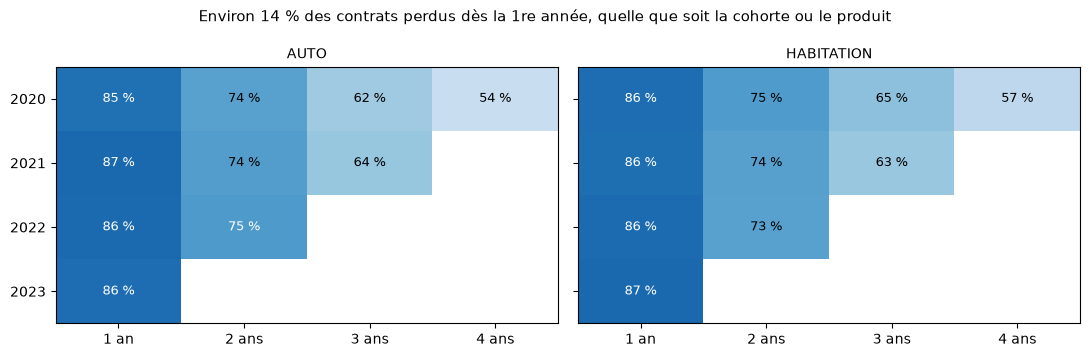

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, produit in zip(axes, ["AUTO", "HABITATION"]):
    m = matrice.loc[produit]
    im = ax.imshow(m.values, cmap="Blues", vmin=40, vmax=100, aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            if not np.isnan(m.values[i, j]):
                ax.text(j, i, f"{m.values[i, j]:.0f} %", ha="center", va="center", fontsize=9,
                        color="white" if m.values[i, j] > 75 else "black")
    ax.set_xticks(range(m.shape[1])); ax.set_xticklabels(m.columns)
    ax.set_yticks(range(m.shape[0])); ax.set_yticklabels(m.index)
    ax.set_title(produit)
fig.suptitle("Environ 14 % des contrats perdus dès la 1re année, quelle que soit la cohorte ou le produit", fontsize=11)
fig.tight_layout(); fig.savefig(FIGURES / "l4_retention_cohortes.png", dpi=150)

**Lecture.** La rétention est très stable d'une cohorte à l'autre et entre produits :
- environ 86 % des contrats sont encore en vigueur au 1ᵉʳ anniversaire ;
- 73 à 75 % au 2ᵉ ;
- 62 à 65 % au 3ᵉ ;
- 54 à 57 % au 4ᵉ (cohorte 2020 seulement).

Aucune cohorte récente ne se dégrade. **Action :** la perte d'environ 14 points la première année est le principal gisement ; un contact avant la première échéance annuelle cible ce moment.

### Part de clients multi-détenteurs

In [4]:
part = cl["multi_detenteur"].mean()
print(f"Clients ayant détenu auto ET habitation : {cl['multi_detenteur'].sum():,} sur {len(cl):,}, soit {100*part:.1f} %")
print(cl["produits"].value_counts().to_frame("clients").assign(**{"%": lambda d: (100 * d["clients"] / d["clients"].sum()).round(1)}))

Clients ayant détenu auto ET habitation : 5,242 sur 14,977, soit 35.0 %
                 clients     %
produits                      
AUTO+HABITATION     5242  35.0
AUTO                5150  34.4
HABITATION          4585  30.6


**Population.** Les clients ayant au moins un contrat valide dans l'entrepôt (2020 à juin 2025). Un client est multi-détenteur s'il a détenu au moins un contrat auto et au moins un contrat habitation sur la période, simultanément ou non.

### Les multi-détenteurs sont-ils plus fidèles ?

Comparer naïvement la rétention des clients qui ont **fini** par détenir les deux produits serait biaisé. Un client qui reste longtemps a plus d'occasions de souscrire un second produit : on mesurerait alors la conséquence de la fidélité, pas sa cause.

On utilise donc deux mesures qui ne regardent pas le futur.

**Mesure 1, au niveau du contrat.** On compare la rétention des contrats souscrits par un client qui **détenait déjà** l'autre produit à la date d'effet et celle des autres contrats.
- Seules les cellules complètes sont retenues.
- La comparaison est prudente : le groupe « sans autre produit » contient aussi les premiers contrats des futurs multi-détenteurs, ce qui l'avantage.

In [5]:
comp = (complet.groupby(["produit", "detenait_autre_produit", "anciennete_annees"])[["nb_retenus", "nb_contrats"]].sum()
        .assign(retention=lambda d: (100 * d["nb_retenus"] / d["nb_contrats"]).round(1)))
tab = comp["retention"].unstack("anciennete_annees")
tab.columns = [f"{c} an{'s' if c > 1 else ''}" for c in tab.columns]
display(tab)
un_an = complet[complet["anciennete_annees"] == 1].groupby("detenait_autre_produit")[["nb_retenus", "nb_contrats"]].sum()
table = np.array([un_an["nb_retenus"], un_an["nb_contrats"] - un_an["nb_retenus"]]).T
khi2, p, _, _ = stats.chi2_contingency(table)
print(f"Rétention à 1 an : {100*un_an.loc[True,'nb_retenus']/un_an.loc[True,'nb_contrats']:.1f} % (détenait l'autre produit, n={un_an.loc[True,'nb_contrats']:,}) "
      f"contre {100*un_an.loc[False,'nb_retenus']/un_an.loc[False,'nb_contrats']:.1f} % (n={un_an.loc[False,'nb_contrats']:,}) ; khi-deux p = {p:.2f}")

1 an  2 ans  3 ans  4 ans
produit    detenait_autre_produit                           
AUTO       False                   86.1   74.6   62.8   53.6
           True                    86.3   73.1   63.7   59.8
HABITATION False                   85.9   74.2   64.4   56.5
           True                    87.7   72.9   62.4   57.9

Rétention à 1 an : 87.0 % (détenait l'autre produit, n=2,537) contre 86.0 % (n=12,852) ; khi-deux p = 0.21


**Mesure 2, au niveau du client, à date fixe.** On part des clients actifs au 1ᵉʳ janvier 2021, 2022, 2023 et 2024. On mesure la part de ceux qui ont encore au moins un contrat un an plus tard, selon qu'ils détenaient un ou deux produits à cette date.

On compare ensuite le résultat à la **fidélité mécanique** : si chaque contrat d'un client à deux produits était conservé avec la même probabilité *p* qu'un contrat de client mono-produit, et indépendamment, ce client garderait au moins un contrat avec la probabilité 1 − (1 − *p*)².

In [6]:
r = ret_cli.assign(retention=lambda d: d["nb_clients_retenus"] / d["nb_clients"])
pivot = r.pivot(index="date_reference", columns="nb_produits", values="retention")
pivot.columns = ["1 produit", "2 produits"]
pivot["attendu mécaniquement pour 2 produits"] = 1 - (1 - pivot["1 produit"]) ** 2
(100 * pivot).round(1).join(r.pivot(index="date_reference", columns="nb_produits", values="nb_clients").add_prefix("clients "))

,1 produit,2 produits,attendu mécaniquement pour 2 produits,clients 1,clients 2
date_reference,,,,,
2021-01-01,86.8,99.5,98.3,3262,186
2022-01-01,88.3,97.8,98.6,5467,585
2023-01-01,87.3,97.8,98.4,7123,1160
2024-01-01,88.3,98.4,98.6,8138,1713


**Lecture.**
- **Au niveau du contrat**, détenir déjà l'autre produit ne change pas la rétention : 86 à 88 % à un an dans les deux groupes, sans différence significative.
- **Au niveau du client**, les détenteurs de deux produits restent clients à 98 % à un an, contre 87 à 88 % pour les mono-détenteurs. C'est presque exactement la fidélité mécanique attendue (98,3 à 98,6 %).

Le multi-équipement fidélise donc le client **par l'addition des contrats**, pas par une moindre résiliation de chacun. **Action :** la vente croisée réduit la perte de clients (il faut résilier deux contrats pour partir). Elle ne dispense pas de travailler la rétention de chaque contrat.

## 2. Valeur observée des clients

**Définition.** Valeur observée = primes acquises − sinistres payés, du 01/01/2020 au 30/06/2025. Les réserves des dossiers ouverts ne sont pas déduites : il s'agit d'une valeur observée, pas projetée. Les frais de gestion et de distribution ne sont pas connus.

**Population.** 14 977 clients ayant au moins un contrat valide.

In [7]:
v = cl["valeur_observee"].sort_values(ascending=False).reset_index(drop=True)
total = v.sum()
print(f"Valeur totale : {total:,.0f} €  |  médiane par client : {v.median():,.0f} €  |  clients à valeur négative : {(v < 0).sum():,} ({100*(v<0).mean():.1f} %)")
print(f"Valeur des clients positifs : {v[v > 0].sum():,.0f} €  |  valeur détruite par les clients négatifs : {v[v < 0].sum():,.0f} €")
concentration = pd.DataFrame([{"clients les plus rentables": f"{int(100*p)} %",
                               "part de la valeur totale %": round(100 * v.head(int(p * len(v))).sum() / total, 1)}
                              for p in [0.01, 0.05, 0.10, 0.20, 0.50]])
concentration

Valeur totale : 8,824,862 €  |  médiane par client : 933 €  |  clients à valeur négative : 1,001 (6.7 %)
Valeur des clients positifs : 17,749,505 €  |  valeur détruite par les clients négatifs : -8,924,643 €


,clients les plus rentables,part de la valeur totale %
0,1 %,8.3
1,5 %,33.0
2,10 %,57.8
3,20 %,96.8
4,50 %,167.7


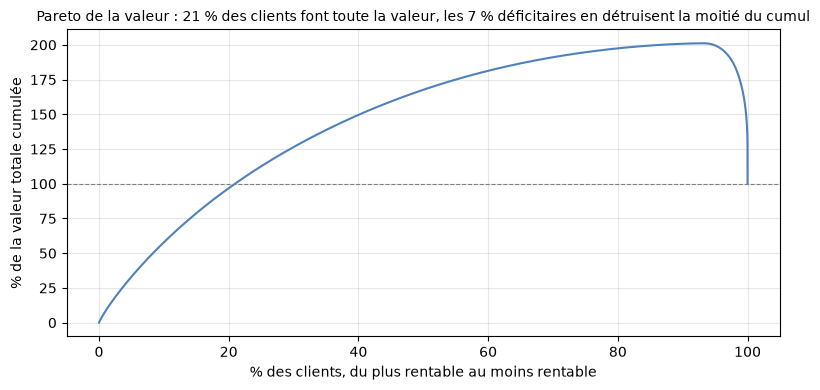

In [8]:
cumul = v.cumsum() / total
x = 100 * np.arange(1, len(v) + 1) / len(v)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, 100 * cumul, color="#4f81bd")
ax.axhline(100, color="grey", ls="--", lw=0.8)
ax.set_xlabel("% des clients, du plus rentable au moins rentable"); ax.set_ylabel("% de la valeur totale cumulée")
ax.set_title("Pareto de la valeur : 21 % des clients font toute la valeur, les 7 % déficitaires en détruisent la moitié du cumul")
ax.grid(alpha=0.3); fig.tight_layout(); fig.savefig(FIGURES / "l4_pareto_valeur.png", dpi=150)

**Lecture.**
- **La courbe monte jusqu'à 201 %** de la valeur totale, puis redescend.
- **Les clients positifs** créent 17,7 M€.
- **Les 1 001 clients déficitaires** (6,7 %) en détruisent 8,9 M€.
- **Concentration :** les 20 % de clients les plus rentables font 97 % de la valeur totale nette, et le point d'équilibre est atteint vers 21 % des clients.

La valeur dépend moins du profil du client que de l'absence de sinistre et de l'ancienneté (tableau suivant).

In [9]:
cl["decile"] = pd.qcut(cl["valeur_observee"].rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)])
profil = cl.groupby("decile", observed=True).agg(
    clients=("client_id", "size"), valeur_moyenne=("valeur_observee", "mean"), primes_moyennes=("primes_acquises", "mean"),
    annees_police=("annees_police", "mean"), sinistres_par_client=("nb_sinistres", "mean"),
    part_multi=("multi_detenteur", "mean"), part_encore_client=("client_actif", "mean"))
profil.round(2)

,clients,valeur_moyenne,primes_moyennes,annees_police,sinistres_par_client,part_multi,part_encore_client
decile,,,,,,,
D1,1498,-5939.10,1112.73,2.48,0.78,0.32,0.55
D2,1498,195.04,255.56,0.75,0.05,0.06,0.57
D3,1497,376.92,424.53,1.27,0.05,0.12,0.64
D4,1498,576.04,622.74,1.79,0.05,0.20,0.68
D5,1498,805.39,845.32,2.45,0.05,0.28,0.77
D6,1497,1065.04,1098.48,2.97,0.05,0.32,0.78
D7,1498,1365.20,1409.36,3.46,0.06,0.42,0.83
D8,1497,1744.89,1784.58,4.01,0.06,0.50,0.86
D9,1498,2295.81,2347.23,4.86,0.07,0.60,0.90


In [10]:
haut, bas = cl[cl["decile"] == "D10"], cl[cl["decile"] == "D1"]
def comparer(col):
    return pd.DataFrame({"tous %": 100 * cl[col].value_counts(normalize=True),
                         "10 % les plus rentables %": 100 * haut[col].value_counts(normalize=True),
                         "10 % les moins rentables %": 100 * bas[col].value_counts(normalize=True)}).round(1).fillna(0)
for col in ["produits", "canaux", "tranche_age", "csp"]:
    display(comparer(col).sort_values("tous %", ascending=False))

,tous %,10 % les plus rentables %,10 % les moins rentables %
produits,,,
AUTO+HABITATION,35.0,68.2,31.8
AUTO,34.4,31.8,26.0
HABITATION,30.6,0.1,42.2


,tous %,10 % les plus rentables %,10 % les moins rentables %
canaux,,,
WEB,31.6,20.7,33.4
AGENT,31.5,27.4,32.2
COURTIER,14.7,9.5,14.2
AGENT+WEB,11.1,20.2,10.5
AGENT+COURTIER,5.7,11.8,5.3
COURTIER+WEB,5.5,10.4,4.4


,tous %,10 % les plus rentables %,10 % les moins rentables %
tranche_age,,,
36-50,36.8,32.7,34.9
51-65,28.6,25.3,29.8
26-35,14.8,14.0,13.9
66+,9.5,10.7,10.2
18-25,8.6,15.1,9.2
Inconnu,1.8,2.2,1.9


,tous %,10 % les plus rentables %,10 % les moins rentables %
csp,,,
EMPLOYE,27.8,27.8,29.4
RETRAITE,20.5,18.8,20.7
CADRE,20.3,21.1,19.6
OUVRIER,14.3,15.7,13.4
INDEPENDANT,10.1,9.9,10.4
ETUDIANT,7.0,6.7,6.6


**Profils.**

*Les 10 % les plus rentables* (3 408 € en moyenne) :
- 6,1 années-police en moyenne, contre 3,0 sur l'ensemble ;
- presque aucun sinistre ;
- 68 % de multi-détenteurs, contre 35 % sur l'ensemble ;
- 95 % encore clients ;
- presque aucun client « habitation seule » (0,1 %), dont la prime est faible ;
- les 18-25 ans y sont surreprésentés (15 % contre 9 %) grâce à leur surprime auto.

*Les 10 % les moins rentables* (−5 939 € en moyenne) : ce sont des clients qui ont eu un sinistre (0,78 par client) ; 42 % ne détiennent que l'habitation.

*Ce qui ne départage pas* : la CSP, l'âge (hors 18-25) et la région ont des répartitions quasi identiques dans les deux groupes.

**Action :** fidéliser et multi-équiper les clients sans sinistre et anciens, qui portent la valeur. Ne pas segmenter le marketing sur la CSP ou la région, qui ne départagent pas la rentabilité.

## 3. Délais de gestion des sinistres

| Délai | Définition | Population |
|---|---|---|
| Déclaration | Survenance → déclaration | Sinistres valides, hors 15 déclarations antérieures à la survenance (règle SIN_06) |
| Premier règlement | Déclaration → premier paiement | Sinistres ayant au moins un paiement |
| Clôture | Déclaration → dernier paiement | Sinistres au statut CLOTURE. Les sources n'ont pas de date de clôture : le dernier paiement en tient lieu |

In [11]:
def quantiles(col):
    g = si.dropna(subset=[col]).groupby("libelle_garantie")[col]
    t = g.quantile([0.25, 0.5, 0.75, 0.9]).unstack()
    t.columns = ["p25", "médiane", "p75", "p90"]
    return t.join(g.size().rename("n")).round(0)

for col, titre in [("delai_declaration_j", "Délai de déclaration (jours)"),
                   ("delai_premier_reglement_j", "Délai de premier règlement (jours)"),
                   ("delai_cloture_j", "Délai de clôture (jours)")]:
    print(titre); display(quantiles(col).sort_values("médiane"))

Délai de déclaration (jours)


,p25,médiane,p75,p90,n
libelle_garantie,,,,,
Tempête,2.0,4.0,10.0,17.0,233
Dommages collision,2.0,5.0,11.0,20.0,687
Dégât des eaux,2.0,5.0,11.0,19.0,587
Responsabilité civile,2.0,5.0,11.0,18.0,440
Vol du véhicule,2.0,5.0,11.0,24.0,165
Bris de glace,2.0,6.0,12.0,19.0,332
Incendie,3.0,6.0,12.0,23.0,107
Vol et cambriolage,2.0,6.0,11.0,25.0,218


Délai de premier règlement (jours)


,p25,médiane,p75,p90,n
libelle_garantie,,,,,
Bris de glace,25.0,45.0,79.0,106.0,69
Incendie,32.0,46.0,76.0,133.0,103
Vol et cambriolage,24.0,46.0,74.0,103.0,192
Vol du véhicule,24.0,48.0,76.0,113.0,95
Dommages collision,29.0,50.0,80.0,118.0,393
Responsabilité civile,29.0,50.0,78.0,109.0,405
Dégât des eaux,31.0,52.0,85.0,117.0,474
Tempête,33.0,54.0,81.0,139.0,114


Délai de clôture (jours)


,p25,médiane,p75,p90,n
libelle_garantie,,,,,
Vol et cambriolage,42.0,71.0,138.0,204.0,179
Vol du véhicule,44.0,72.0,142.0,201.0,93
Incendie,45.0,76.0,146.0,189.0,98
Dommages collision,46.0,80.0,144.0,209.0,379
Tempête,50.0,84.0,142.0,221.0,110
Dégât des eaux,47.0,88.0,139.0,223.0,462
Responsabilité civile,50.0,88.0,137.0,201.0,388
Bris de glace,42.0,92.0,142.0,243.0,64


Premier règlement, part des 1,845 dossiers payés réglés en moins de :


,≤ 30 j %,≤ 60 j %,≤ 90 j %,≤ 180 j %
0,27.1,61.5,81.0,98.3


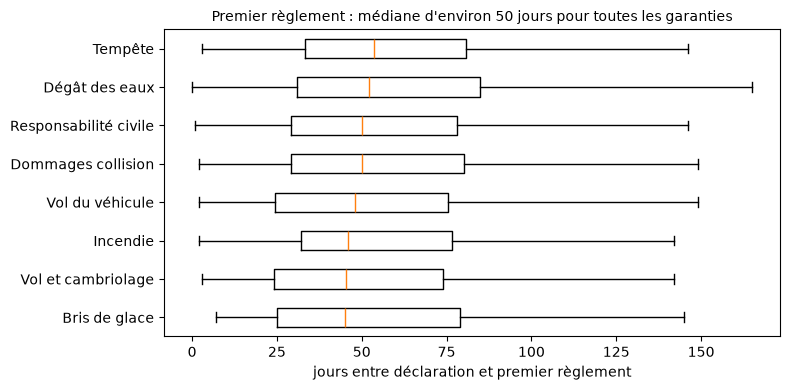

In [12]:
p = si.dropna(subset=["delai_premier_reglement_j"])
seuils = pd.DataFrame({f"≤ {s} j %": [round(100 * (p["delai_premier_reglement_j"] <= s).mean(), 1)] for s in [30, 60, 90, 180]})
print(f"Premier règlement, part des {len(p):,} dossiers payés réglés en moins de :"); display(seuils)
fig, ax = plt.subplots(figsize=(8, 4))
ordre = p.groupby("libelle_garantie")["delai_premier_reglement_j"].median().sort_values().index
ax.boxplot([p.loc[p["libelle_garantie"] == g, "delai_premier_reglement_j"] for g in ordre], orientation="horizontal", showfliers=False)
ax.set_yticks(range(1, len(ordre) + 1)); ax.set_yticklabels(ordre); ax.set_xlabel("jours entre déclaration et premier règlement")
ax.set_title("Premier règlement : médiane d'environ 50 jours pour toutes les garanties")
fig.tight_layout(); fig.savefig(FIGURES / "l4_delais_premier_reglement.png", dpi=150)

**Lecture.**
- **Déclaration :** les assurés déclarent vite, avec une médiane de 4 à 6 jours selon la garantie et 90 % des dossiers en moins de 26 jours.
- **Premier règlement :** médiane de 45 à 54 jours selon la garantie. Les différences entre garanties sont faibles : le délai dépend du processus de gestion, pas de la complexité du sinistre. Pour un incendie, plus lourd, il n'est pas plus long.
- **Clôture :** médiane de 71 à 92 jours.

**Faute d'engagement de délai dans les sources**, on mesure la part des dossiers payés sous 30, 60 et 90 jours (tableau ci-dessus). **Action :** fixer un objectif de premier règlement, par exemple 60 jours, et le suivre dans la page Exploitation du dashboard.

## 4. Audits antifraude

**Population.** Les audits ne portent que sur les dossiers **contrôlés** : 370 audits valides sur 2 783 sinistres valides (13,3 %). Le taux de confirmation ne vaut que pour cette population. On ne peut **pas** en déduire un taux de fraude du portefeuille, car les dossiers ont été choisis et non tirés au hasard.

In [13]:
a = si[si["est_audite"]]
nf = int((a["fraude_confirmee"] == True).sum())
bas_ic, haut_ic = stats.binomtest(nf, len(a)).proportion_ci()
print(f"{len(a)} dossiers audités, {nf} fraudes confirmées : taux de confirmation {100*nf/len(a):.1f} % (IC 95 % {100*bas_ic:.1f} – {100*haut_ic:.1f})")

si["tranche_reserve"] = pd.cut(si["reserve_initiale"], [-1, 0, 2000, 5000, 10000, 1e9], labels=["0 €", "≤ 2 k€", "2–5 k€", "5–10 k€", "> 10 k€"])
si["tranche_declaration"] = pd.cut(si["delai_declaration_j"], [-1, 7, 30, 1e4], labels=["≤ 7 j", "8–30 j", "> 30 j"])
si["anciennete_contrat"] = np.where(si["anciennete_contrat_j"] < 90, "< 90 j", "≥ 90 j")

def par_critere(col):
    g = si.groupby(col, observed=True).agg(sinistres=("sinistre_id", "size"), audites=("est_audite", "sum"),
                                           fraudes=("fraude_confirmee", lambda x: int((x == True).sum())))
    g["% audités"] = (100 * g["audites"] / g["sinistres"]).round(1)
    g["% fraude parmi audités"] = (100 * g["fraudes"] / g["audites"]).round(1)
    return g

for col, titre in [("libelle_garantie", "Garantie"), ("tranche_reserve", "Réserve initiale"),
                   ("tranche_declaration", "Délai de déclaration"), ("anciennete_contrat", "Ancienneté du contrat au sinistre"),
                   ("canal_distribution", "Canal")]:
    print(titre); display(par_critere(col))

370 dossiers audités, 37 fraudes confirmées : taux de confirmation 10.0 % (IC 95 % 7.1 – 13.5)
Garantie


,sinistres,audites,fraudes,% audités,% fraude parmi audités
libelle_garantie,,,,,
Bris de glace,332,13,4,3.9,30.8
Dommages collision,688,66,9,9.6,13.6
Dégât des eaux,593,68,6,11.5,8.8
Incendie,108,49,4,45.4,8.2
Responsabilité civile,441,104,2,23.6,1.9
Tempête,234,11,0,4.7,0.0
Vol du véhicule,167,19,5,11.4,26.3
Vol et cambriolage,220,40,7,18.2,17.5


Réserve initiale


,sinistres,audites,fraudes,% audités,% fraude parmi audités
tranche_reserve,,,,,
0 €,838,20,4,2.4,20.0
≤ 2 k€,969,57,7,5.9,12.3
2–5 k€,478,54,10,11.3,18.5
5–10 k€,278,112,9,40.3,8.0
> 10 k€,220,127,7,57.7,5.5


Délai de déclaration


,sinistres,audites,fraudes,% audités,% fraude parmi audités
tranche_declaration,,,,,
≤ 7 j,1754,200,0,11.4,0.0
8–30 j,889,109,4,12.3,3.7
> 30 j,126,58,32,46.0,55.2


Ancienneté du contrat au sinistre


,sinistres,audites,fraudes,% audités,% fraude parmi audités
anciennete_contrat,,,,,
< 90 j,319,53,11,16.6,20.8
≥ 90 j,2464,317,26,12.9,8.2


Canal


,sinistres,audites,fraudes,% audités,% fraude parmi audités
canal_distribution,,,,,
AGENT,1148,163,20,14.2,12.3
COURTIER,566,69,6,12.2,8.7
WEB,1069,138,11,12.9,8.0


**Critères de sélection et de confirmation.**

*Comment les dossiers sont choisis aujourd'hui :* surtout par montant et par garantie. 58 % des dossiers de plus de 10 k€ sont audités, contre 2 % des dossiers sans réserve. Les garanties les plus contrôlées sont l'incendie (45 %) et la RC (24 %).

*Où les fraudes se confirment :* ce ne sont pas les mêmes dossiers.
- **Déclaration tardive (plus de 30 jours) :** 55 % de confirmation (32 fraudes sur 58 audits), contre 0 sur 200 audits pour les déclarations de moins de 7 jours.
- **Sinistre dans les 90 jours suivant la souscription :** 21 % de confirmation, contre 8 %.
- **Vol et bris de glace :** 26 % (vol du véhicule), 18 % (vol et cambriolage) et 31 % (bris de glace), contre 2 % pour la RC.
- **Gros dossiers (plus de 10 k€) :** seulement 5,5 % de confirmation.

In [14]:
tests = []
for col, groupe in [("tranche_declaration", "> 30 j"), ("anciennete_contrat", "< 90 j")]:
    t = pd.crosstab(a.assign(g=si.loc[a.index, col] == groupe)["g"], a["fraude_confirmee"] == True)
    res = stats.fisher_exact(t)
    tests.append({"critère": f"{col} = {groupe}", "rapport de cotes": round(res.statistic, 2), "p (Fisher exact)": f"{res.pvalue:.1e}"})
pd.DataFrame(tests)

,critère,rapport de cotes,p (Fisher exact)
0,tranche_declaration = > 30 j,75.57,4.5e-25
1,anciennete_contrat = < 90 j,2.93,1.1e-02


**Tests.** Les effectifs sont petits (37 fraudes) : on utilise le test exact de Fisher, sans approximation, sur les dossiers audités.
- La déclaration tardive est très fortement liée à la fraude confirmée.
- Le contrat récent l'est aussi, au seuil de 5 %.

### Intérêt des audits au regard des montants

In [15]:
f = a[a["fraude_confirmee"] == True]
montants = pd.DataFrame({
    "dossiers": [len(a), len(f)],
    "réserve initiale €": [a["reserve_initiale"].sum(), f["reserve_initiale"].sum()],
    "charge (payé + réserve restante) €": [a["charge_totale"].sum(), f["charge_totale"].sum()],
    "payé €": [a["montant_paye"].sum(), f["montant_paye"].sum()],
    "dont payé avant la date d'audit €": [a["montant_paye_avant_audit"].sum(), f["montant_paye_avant_audit"].sum()],
}, index=["tous les dossiers audités", "fraudes confirmées"]).round(0)
montants["payé après l'audit €"] = montants["payé €"] - montants["dont payé avant la date d'audit €"]
display(montants)
print(f"Fraudes confirmées : {f['statut'].value_counts().to_dict()}")
print(f"Délai de l'audit après déclaration : médiane {a['delai_audit_j'].median():.0f} j (de {a['delai_audit_j'].min():.0f} à {a['delai_audit_j'].max():.0f} j)")
tardifs = si[si["tranche_declaration"] == "> 30 j"]
print(f"Déclarations tardives non auditées : {int((~tardifs['est_audite']).sum())} dossiers, charge {tardifs.loc[~tardifs['est_audite'], 'charge_totale'].sum():,.0f} €")

,dossiers,réserve initiale €,charge (payé + réserve restante) €,payé €,dont payé avant la date d'audit €,payé après l'audit €
tous les dossiers audités,370,5236264.0,6520414.0,6415578.0,3964618.0,2450960.0
fraudes confirmées,37,417905.0,506127.0,487280.0,80703.0,406577.0


Fraudes confirmées : {'CLOTURE': 30, 'SANS_SUITE': 4, 'OUVERT': 3}
Délai de l'audit après déclaration : médiane 53 j (de 10 à 89 j)
Déclarations tardives non auditées : 68 dossiers, charge 126,684 €


**Lecture.**
- **Les fraudes confirmées représentent 506 k€** de charge, sur 37 dossiers.
- **Elles ont pourtant été payées :** 487 k€, dont seulement 81 k€ avant la date d'audit. 30 de ces dossiers sont au statut « clôturé » et non « rejeté ». La confirmation de fraude ne déclenche donc ni l'arrêt des paiements ni, d'après les sources, un rejet.
- **Les audits arrivent tard :** 53 jours en médiane après la déclaration, alors que le premier règlement arrive vers 50 jours.

L'intérêt actuel des audits est donc faible en montants évités. Il pourrait être bien plus élevé.

**Actions :**
1. Suspendre les paiements dès qu'un audit confirme la fraude, et engager le recouvrement des 406 k€ versés après confirmation.
2. Réorienter la sélection vers les déclarations tardives et les sinistres survenus dans les 90 jours suivant la souscription, plutôt que vers les seuls gros montants. Il reste 68 déclarations tardives non auditées, à examiner en priorité.
3. Auditer avant le premier règlement.

*Limite : rien ne permet de savoir si les fraudes confirmées ont fait l'objet d'un recouvrement hors des sources fournies.*